# LoRa: transmitir, recibir una vez, detectar y demodular

Ejecutar en orden. La conexión requiere VPN. Construimos `hola mundo`, adaptamos la señal al SDR y hacemos una sola lectura. Después ejecutamos la celda de cierre, también si falla la recepción. Con el SDR cerrado, graficamos `rxSignal`, buscamos una trama completa y recuperamos sus bytes.

Las muestras quedan en memoria; no se crean archivos de resultados. La comprobación local previa y el procesamiento de la captura real se muestran por separado.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import resample_poly

## 1. Señal LoRa de clase, normalizada

SF=8, ocho upchirps, 2¼ downchirps y diez bytes de `hola mundo`. A 125 kS/s, el período con cuatro símbolos de silencio tiene 6208 muestras y dura 49,664 ms.

Dividimos toda la señal por su mayor módulo: **pico 1 y componentes I/Q entre −1 y +1**, conservando la fase y el silencio. El gráfico de rampas usa la misma representación de clase 4: índice modular escalado a kHz; no es una medición de la frecuencia RF.

In [2]:
def modular_simbolo(valor, k, N):
    """Genera el chirp del símbolo valor usando la ecuación discreta de clase."""
    k = np.asarray(k)
    fase_discreta = ((valor + k) % N) * k / N       # El módulo N reinicia la rampa; valor selecciona el símbolo transmitido.
    return np.exp(1j * 2 * np.pi * fase_discreta) / np.sqrt(N)      # La división por sqrt(N) deja al símbolo con energía unitaria.


# Parámetros de nuestra trama; se definen donde la construimos.
B = 125_000
SF = 8
mensaje = 'hola mundo'

N = 2**SF
k = np.arange(N)                 # Índices 0, 1, ..., 255 dentro del símbolo.
bytes_enviados = mensaje.encode('ascii')  # Convierte el texto en sus valores de byte.
cantidad_bytes = len(bytes_enviados)

# El símbolo cero genera el upchirp de referencia.
upchirp = modular_simbolo(0, k, N)
downchirp = np.conj(upchirp)      # El conjugado invierte el signo de la fase.
preambulo = np.tile(upchirp, 8)   # tile repite el vector ocho veces.
sincronizacion = np.concatenate((downchirp, downchirp, downchirp[:N // 4]))
cabecera = np.concatenate((preambulo, sincronizacion))

# Modulamos cada byte con la función que ya usamos en clase.
simbolos_tx = []
for valor in bytes_enviados:
    simbolos_tx.append(modular_simbolo(valor, k, N))
payload_tx = np.concatenate(simbolos_tx)
trama = np.concatenate((cabecera, payload_tx))
periodo = np.concatenate((trama, np.zeros(4 * N)))

# Normalizamos la señal de clase: pico de módulo 1, con I y Q dentro de [-1, +1].
periodo = periodo / np.max(np.abs(periodo))

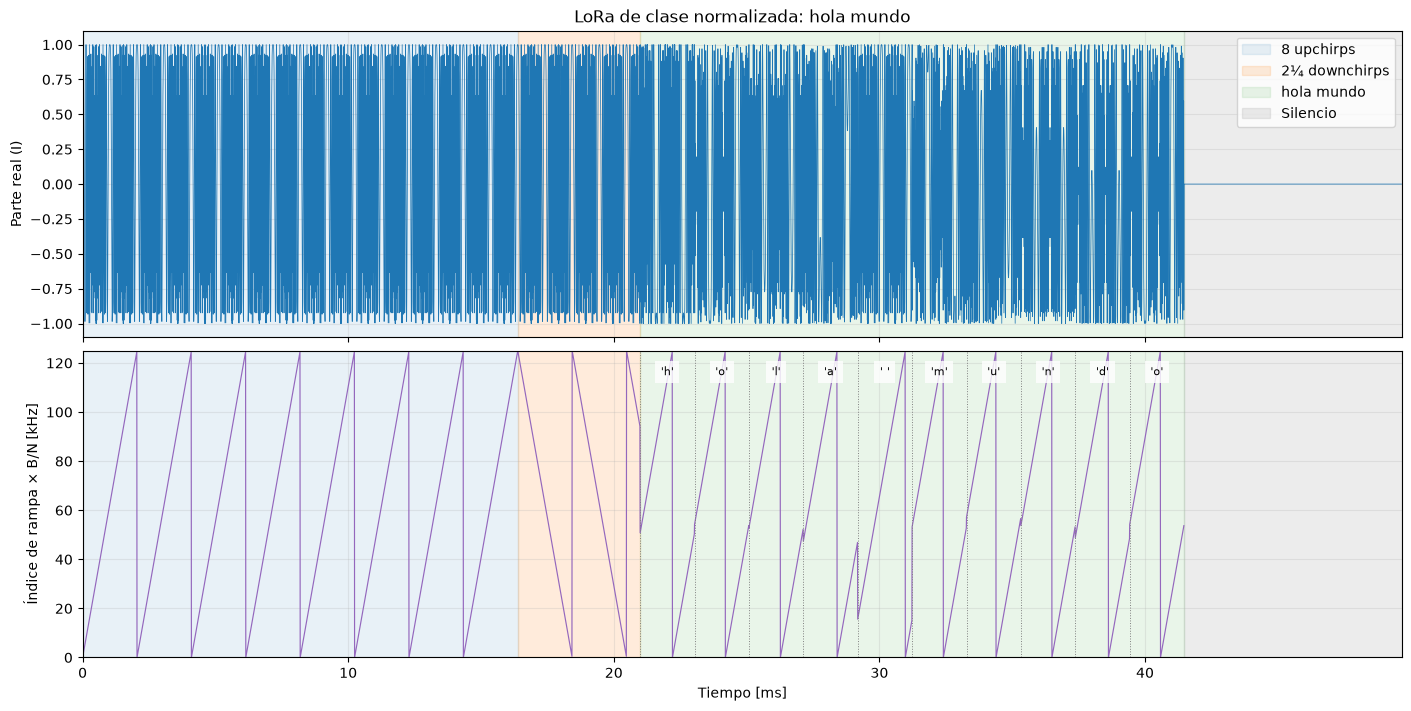

In [3]:
# Rampas del modelo de clase 4, en el mismo orden que los chirps de la trama.
rampa_up = k * B / N
rampa_down = B - rampa_up
rampa_payload = np.concatenate([np.mod(valor + k, N) * B / N for valor in bytes_enviados])
rampa_trama = np.concatenate((np.tile(rampa_up, 8), rampa_down, rampa_down,
                              rampa_down[:N // 4], rampa_payload))
# NaN deja el silencio sin curva: allí no hay un chirp con frecuencia definida.
rampa_periodo = np.concatenate((rampa_trama, np.full(4 * N, np.nan)))
tiempo_ms = np.arange(len(periodo)) / B * 1000

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, constrained_layout=True)
axes[0].plot(tiempo_ms, periodo.real, lw=0.55)
axes[0].set(title='LoRa de clase normalizada: hola mundo', ylabel='Parte real (I)', ylim=(-1.1, 1.1))
axes[1].plot(tiempo_ms, rampa_periodo / 1000, lw=0.85, color='tab:purple')
axes[1].set(xlabel='Tiempo [ms]', ylabel='Índice de rampa × B/N [kHz]', ylim=(0, B / 1000))

for ax in axes:
    ax.axvspan(0, len(preambulo)/B*1000, color='tab:blue', alpha=0.1, label='8 upchirps')
    ax.axvspan(len(preambulo)/B*1000, len(cabecera)/B*1000, color='tab:orange', alpha=0.15, label='2¼ downchirps')
    ax.axvspan(len(cabecera)/B*1000, len(trama)/B*1000, color='tab:green', alpha=0.1, label='hola mundo')
    ax.axvspan(len(trama)/B*1000, len(periodo)/B*1000, color='gray', alpha=0.15, label='Silencio')
    ax.set_xlim(0, len(periodo)/B*1000)
    ax.grid(alpha=0.25)
axes[0].legend(loc='upper right')
for posicion, caracter in enumerate(mensaje):
    inicio = len(cabecera) + posicion * N
    axes[1].axvline(inicio / B * 1000, color='gray', ls=':', lw=0.7)
    axes[1].text((inicio + N/2) / B * 1000, 0.92 * B / 1000, repr(caracter), ha='center', fontsize=8,
                 bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none'})
plt.show()

## 2. Adaptar y normalizar antes de transmitir

Interpolamos por 16 para pasar de 125 kS/s a 2 MS/s conservando la duración: **6208 → 99328 muestras**. Como el filtro puede modificar el pico, volvemos a dividir por el mayor módulo: la señal final también queda con **pico 1 e I/Q dentro de [−1, +1]**. El factor 32767 se aplica después, sólo al transmitir.

Antes de conectar vemos la señal TX final y su espectro de banda base. La FFT muestra su contenido en frecuencia; el gráfico de rampas anterior es la representación didáctica de clase 4.

In [4]:
# resample_poly interpola y filtra; no se limita a repetir cada muestra.
senal_tx = resample_poly(periodo, 16, 1)
senal_tx = senal_tx / np.max(np.abs(senal_tx))  # abs: módulo; max: el pico del vector.
print('Muestras TX:', len(senal_tx), '| Pico de módulo:', np.max(np.abs(senal_tx)))
print('Rango I:', senal_tx.real.min(), 'a', senal_tx.real.max())
print('Rango Q:', senal_tx.imag.min(), 'a', senal_tx.imag.max())

Muestras TX: 99328 | Pico de módulo: 1.0
Rango I: -0.7780746609703206 a 0.9204168205717952
Rango Q: -0.7392526865705916 a 0.7203353565740763


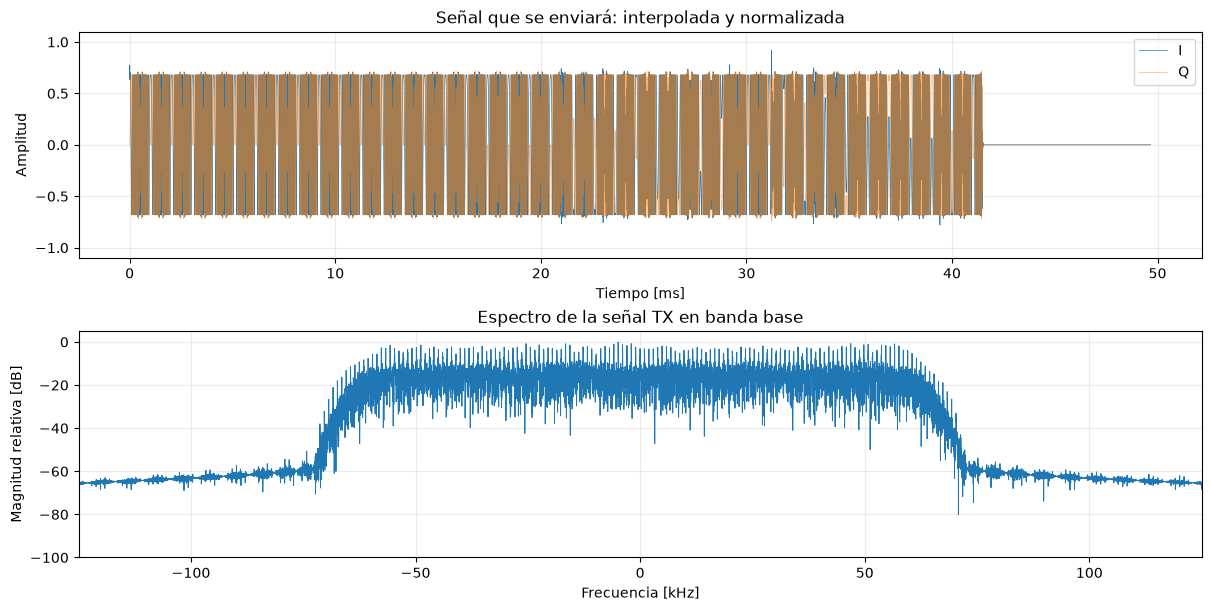

In [5]:
# Esta celda sólo grafica; no conecta ni manda muestras al SDR.
tiempo_tx_ms = np.arange(len(senal_tx)) / 2_000_000 * 1000
# fft obtiene el espectro; fftshift centra los 0 Hz; fftfreq construye el eje en Hz.
espectro_tx = np.fft.fftshift(np.fft.fft(senal_tx))
frecuencias_tx = np.fft.fftshift(np.fft.fftfreq(len(senal_tx), d=1/2_000_000))
# Magnitud relativa al pico en dB; maximum evita calcular log10(0).
espectro_db = 20 * np.log10(np.maximum(np.abs(espectro_tx) / np.max(np.abs(espectro_tx)), 1e-12))

fig, axes = plt.subplots(2, 1, figsize=(12, 6), constrained_layout=True)
axes[0].plot(tiempo_tx_ms, senal_tx.real, lw=0.5, label='I')
axes[0].plot(tiempo_tx_ms, senal_tx.imag, lw=0.5, alpha=0.6, label='Q')
axes[0].set(title='Señal que se enviará: interpolada y normalizada',
            xlabel='Tiempo [ms]', ylabel='Amplitud', ylim=(-1.1, 1.1))
axes[0].legend()
axes[1].plot(frecuencias_tx / 1000, espectro_db, lw=0.7)
axes[1].set(title='Espectro de la señal TX en banda base', xlabel='Frecuencia [kHz]',
            ylabel='Magnitud relativa [dB]', xlim=(-B/1000, B/1000), ylim=(-100, 5))
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()

### Demodular localmente la señal normalizada

Usamos **`senal_tx`**, la señal que preparamos para transmitir. Volvemos de 2 MS/s a 125 kS/s con filtrado y quitamos la cabecera: quedan diez símbolos de 256 muestras. Para cada símbolo hacemos el dechirp y buscamos el pico de la FFT, igual que en clase.

En esta comprobación local conocemos el inicio y no hay ruido ni radio. No es una detección de trama ni una demodulación de `rxSignal`. El gráfico muestra la señal recuperada a 125 kS/s, las rampas **reconstruidas con los bytes decididos** y la FFT después del dechirp de los diez símbolos. Comparamos con `hola mundo` sólo al terminar de decodificar.

In [6]:
# Filtrar y decimar por 16: 99328 -> 6208 muestras, de nuevo a la tasa de clase.
senal_local = resample_poly(senal_tx, 1, 16)
payload_local = senal_local[len(cabecera):len(trama)]  # 2560 muestras, sin cabecera ni silencio.
simbolos_locales = payload_local.reshape(cantidad_bytes, N)  # 10 filas de 256 muestras.

# Misma operación de demodular_simbolo de clase: dechirp y máximo de energía de la FFT.
downchirp_local = np.exp(-2j * np.pi * k**2 / N)
valores_locales = []
espectros_locales = []
for simbolo in simbolos_locales:
    dechirpeada = simbolo * downchirp_local
    espectro = np.fft.fft(dechirpeada)
    valor = int(np.argmax(np.abs(espectro)**2))  # Bin de mayor energía = valor del byte.
    valores_locales.append(valor)
    espectros_locales.append(espectro)

mensaje_local = bytes(valores_locales)
print('Bytes decodificados:', valores_locales)
print('Mensaje:', mensaje_local)
print('Coincide con el enviado:', mensaje_local == bytes_enviados)

Bytes decodificados: [104, 111, 108, 97, 32, 109, 117, 110, 100, 111]
Mensaje: b'hola mundo'
Coincide con el enviado: True


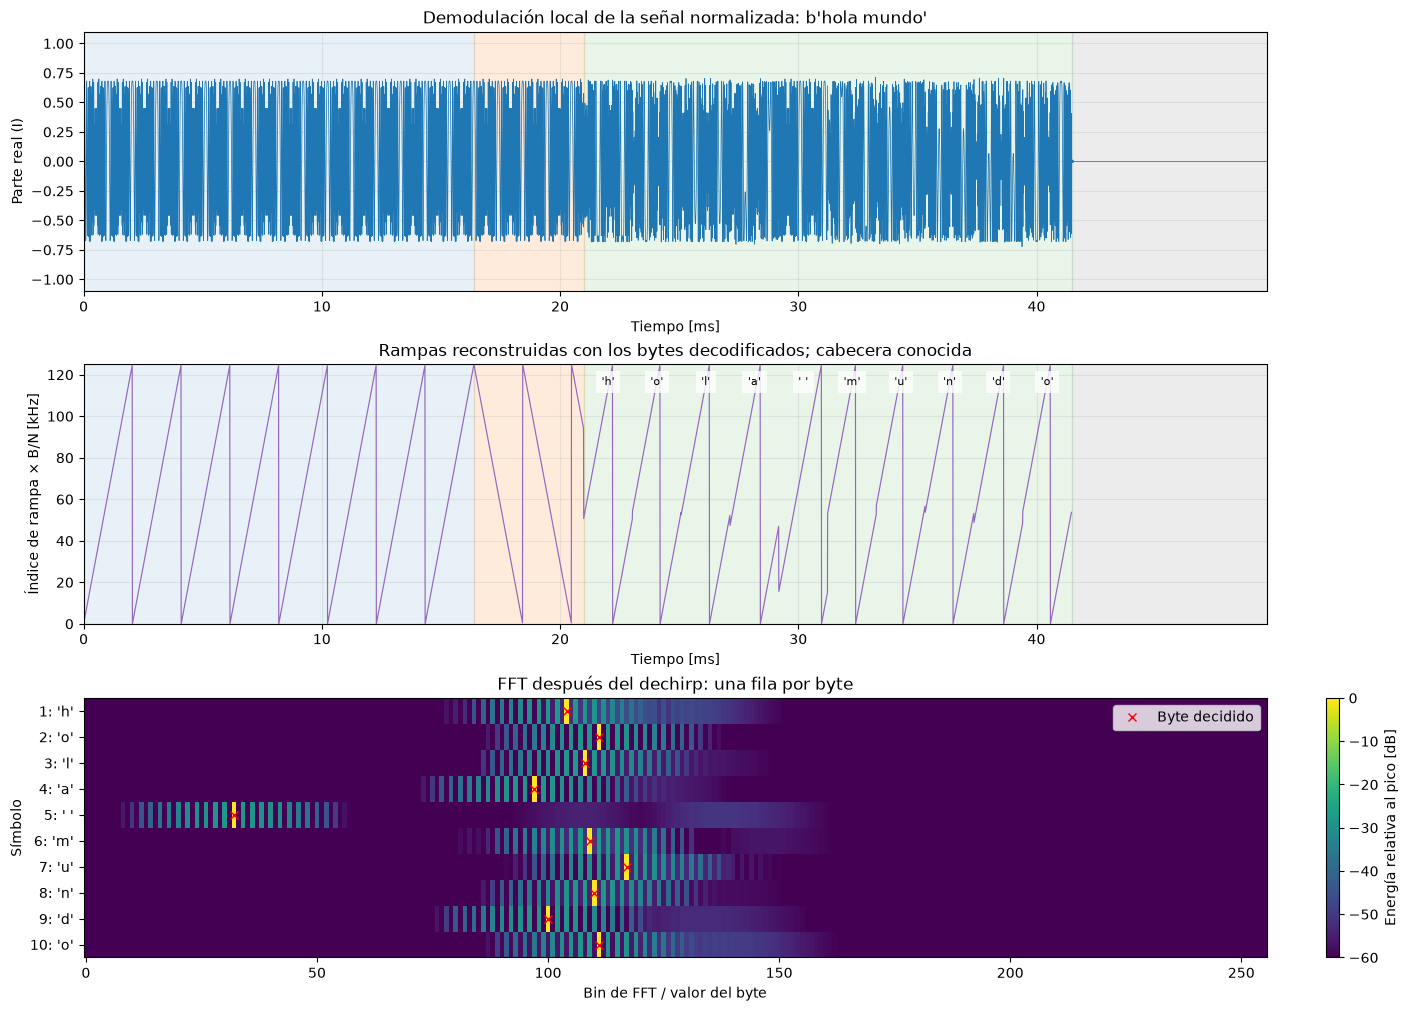

In [7]:
# Dibujamos las rampas a partir de los valores DECODIFICADOS, con el formato de clase 4.
rampa_payload_local = np.concatenate([np.mod(valor + k, N) * B / N for valor in valores_locales])
rampa_local = np.concatenate((np.tile(rampa_up, 8), rampa_down, rampa_down,
                              rampa_down[:N // 4], rampa_payload_local, np.full(4 * N, np.nan)))
tiempo_local_ms = np.arange(len(senal_local)) / B * 1000
fig, axes = plt.subplots(3, 1, figsize=(14, 10), constrained_layout=True)
axes[0].plot(tiempo_local_ms, senal_local.real, lw=0.55)
axes[0].set(title=f'Demodulación local de la señal normalizada: {mensaje_local!r}',
            xlabel='Tiempo [ms]', ylabel='Parte real (I)', ylim=(-1.1, 1.1))
axes[1].plot(tiempo_local_ms, rampa_local / 1000, lw=0.85, color='tab:purple')
axes[1].set(title='Rampas reconstruidas con los bytes decodificados; cabecera conocida',
            xlabel='Tiempo [ms]', ylabel='Índice de rampa × B/N [kHz]', ylim=(0, B / 1000))
for ax in axes[:2]:
    ax.axvspan(0, len(preambulo)/B*1000, color='tab:blue', alpha=0.1)
    ax.axvspan(len(preambulo)/B*1000, len(cabecera)/B*1000, color='tab:orange', alpha=0.15)
    ax.axvspan(len(cabecera)/B*1000, len(trama)/B*1000, color='tab:green', alpha=0.1)
    ax.axvspan(len(trama)/B*1000, len(periodo)/B*1000, color='gray', alpha=0.15)
    ax.set_xlim(0, len(periodo)/B*1000)
    ax.grid(alpha=0.25)
for posicion, valor in enumerate(valores_locales):
    centro_ms = (len(cabecera) + (posicion + 0.5)*N) / B * 1000
    axes[1].text(centro_ms, 0.92 * B / 1000, repr(chr(valor)), ha='center', fontsize=8,
                 bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none'})

# Cada fila muestra los 256 bins de un símbolo; el punto rojo señala el byte decidido.
energia_local = np.abs(np.asarray(espectros_locales))**2
# keepdims conserva una columna de máximos para dividir cada fila por su propio pico.
energia_local_db = 10 * np.log10(np.maximum(energia_local / energia_local.max(axis=1, keepdims=True), 1e-12))
imagen = axes[2].imshow(energia_local_db, aspect='auto', interpolation='nearest', vmin=-60, vmax=0)
axes[2].plot(valores_locales, np.arange(cantidad_bytes), 'rx', label='Byte decidido')
axes[2].set(title='FFT después del dechirp: una fila por byte', xlabel='Bin de FFT / valor del byte', ylabel='Símbolo')
axes[2].set_yticks(np.arange(cantidad_bytes), [f'{i+1}: {chr(v)!r}' for i, v in enumerate(valores_locales)])
axes[2].legend(loc='upper right')
fig.colorbar(imagen, ax=axes[2], label='Energía relativa al pico [dB]')
plt.show()

## 3. Conectar y configurar el SDR

TX cíclico: la radio repite el período de 49,664 ms mientras recibimos un bloque. Una lectura de 524288 muestras a 2 MS/s abarca 262,144 ms. Usamos antenas, con `loopback=0`.

In [8]:
import adi

sdr = adi.Pluto('ip:192.168.1.34')
sdr.tx_destroy_buffer()                    # Limpiar buffers anteriores.
sdr.rx_destroy_buffer()
sdr.loopback = 0
sdr.sample_rate = 2_000_000                 # Muestras/s para TX y RX.
sdr.tx_lo = 915_000_000                     # Portadoras en Hz.
sdr.rx_lo = 915_000_000
sdr.tx_rf_bandwidth = 2_000_000              # Filtros RF en Hz.
sdr.rx_rf_bandwidth = 2_000_000
sdr.tx_hardwaregain_chan0 = -45             # Ganancia TX en dB, como en el HowTo.
sdr.gain_control_mode_chan0 = 'slow_attack'
sdr.rx_buffer_size = 2**19                  # 524288 muestras por llamada a rx().
sdr.tx_cyclic_buffer = True

## 4. Transmitir y recibir una vez

In [9]:
sdr.tx(senal_tx*(2**15-1))  # Escalado del HowTo: 32767, una sola vez.
rxSignal = sdr.rx()

## 5. Cerrar el SDR

Misma secuencia de cierre del HowTo. Todo el procesamiento siguiente usa `rxSignal` en memoria y se hace con el SDR ya cerrado.

In [10]:
# Since it is not possible to turn off Tx, it is configured to transmit at low power and on a different frequency than Rx.
sdr.tx_destroy_buffer()
sdr.tx_hardwaregain_chan0 = -89 
sdr.tx_lo                 = int(2400e6)
sdr.rx_lo                 = int(950e6)
sdr.tx(np.zeros(2048))

# Destroy radio object
del(sdr)

## 6. Graficar lo recibido y buscar chirps visualmente

Los tres gráficos usan `rxSignal[0:10000]`: las primeras **10.000 muestras = 5 ms**, aproximadamente **2,44 símbolos**. El tercero es un **espectrograma calculado desde la recepción**: horizontal = muestra/tiempo, vertical = frecuencia y color = potencia relativa. Un chirp se ve como un trazo que barre frecuencias; el ruido suele verse más disperso.

Este gráfico no reconstruye rampas a partir de bytes: permite observar si hay barridos en las muestras reales, aunque todavía no hayamos detectado ni decodificado nada. Las rampas de clase 4 representan el índice modular del modelo; el espectrograma puede mostrar saltos y plegamientos distintos de ese dibujo. 0 Hz corresponde a la portadora de 915 MHz. Para ver más símbolos, ampliá el recorte `rxSignal[0:10000]` de la siguiente celda.

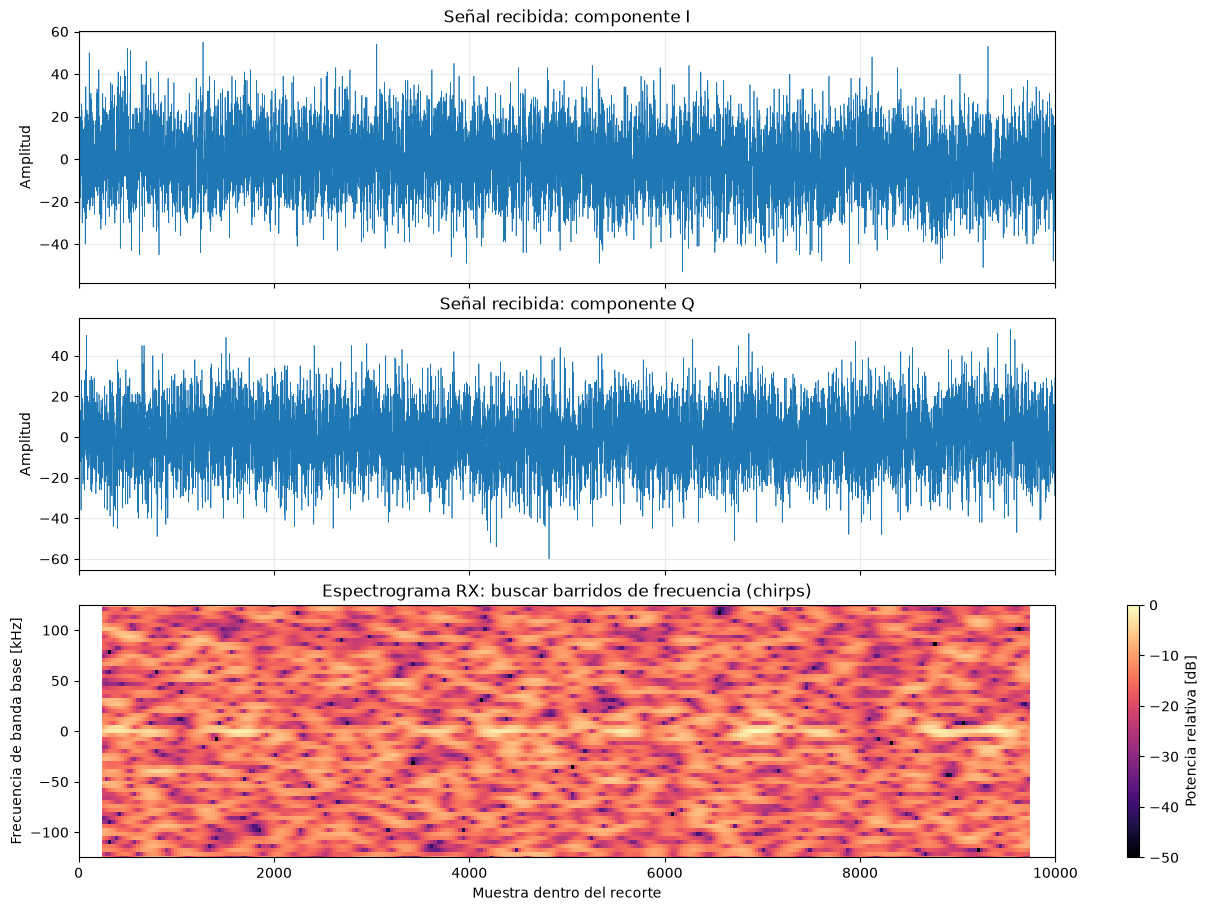

In [11]:
from scipy.signal import spectrogram

segmento_rx = np.asarray(rxSignal[0:10000])  # Un único recorte para los tres gráficos.
fs_grafico_rx = 2_000_000                  # Misma tasa configurada en el SDR.
indices_rx = np.arange(len(segmento_rx))
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, constrained_layout=True)
axes[0].plot(indices_rx, segmento_rx.real, lw=0.5)
axes[0].set(title='Señal recibida: componente I', ylabel='Amplitud')
axes[1].plot(indices_rx, segmento_rx.imag, lw=0.5)
axes[1].set(title='Señal recibida: componente Q', ylabel='Amplitud')

# FFT en ventanas de 512 muestras (0,256 ms), avanzando 32 muestras cada vez.
# El solapamiento hace visible cómo se desplaza la energía en frecuencia.
# Quitamos sólo la continua en este análisis para que no tape los barridos.
frecuencias_spec_rx, tiempos_spec_rx, potencia_spec_rx = spectrogram(
    segmento_rx - np.mean(segmento_rx), fs=fs_grafico_rx,
    window='hann', nperseg=512, noverlap=480,
    detrend=False, return_onesided=False, scaling='density', mode='psd')
# Para I/Q complejo incluimos frecuencias negativas; fftshift ordena de -Fs/2 a +Fs/2.
frecuencias_spec_rx = np.fft.fftshift(frecuencias_spec_rx)
potencia_spec_rx = np.fft.fftshift(potencia_spec_rx, axes=0)
potencia_spec_db = 10*np.log10(np.maximum(potencia_spec_rx / max(potencia_spec_rx.max(), 1e-30), 1e-12))

# Tiempo × Fs vuelve a índices para alinear este gráfico con los de I y Q.
imagen = axes[2].pcolormesh(tiempos_spec_rx * fs_grafico_rx,
                            frecuencias_spec_rx / 1000, potencia_spec_db,
                            shading='auto', cmap='magma', vmin=-50, vmax=0)
axes[2].set(title='Espectrograma RX: buscar barridos de frecuencia (chirps)',
            xlabel='Muestra dentro del recorte', ylabel='Frecuencia de banda base [kHz]',
            ylim=(-125, 125), xlim=(0, len(segmento_rx)))
fig.colorbar(imagen, ax=axes[2], label='Potencia relativa [dB]')
for ax in axes[:2]:
    ax.grid(alpha=0.25)
plt.show()

/tmp/ipykernel_170358/3865464063.py:4: MatplotlibDeprecationWarning: Passing the NFFT parameter of psd() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.psd(rxSignal[0:10000], len(rxSignal[0:10000]), 125_000, color='C1') # nose q sampling rate poner


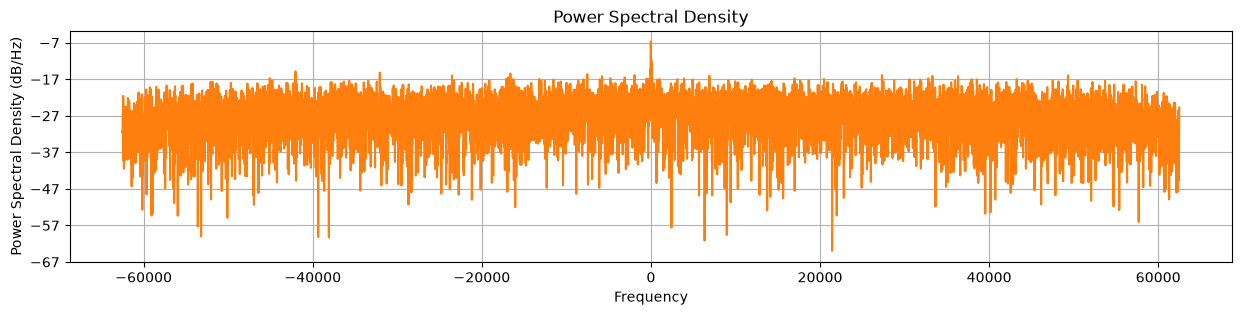

In [12]:
plt.subplots(figsize=(15, 3))
plt.grid()
plt.title("Power Spectral Density")
plt.psd(rxSignal[0:10000], len(rxSignal[0:10000]), 125_000, color='C1') # nose q sampling rate poner
plt.show()

## 7. Detectar el inicio en la captura del SDR

A diferencia de la comprobación local, **no sabemos dónde empieza la trama dentro de `rxSignal`**. Buscamos la cabecera completa: ocho upchirps y 2¼ downchirps. La correlación normalizada compara formas y divide por sus energías; su puntaje va de 0 a 1 y no depende de una escala de amplitud constante.

`umbral_rx = 0.2` y las frecuencias de −250 a +250 Hz son ajustes del procesamiento, no del SDR. Probamos esas correcciones porque un pequeño error de frecuencia reduce la coincidencia con la cabecera. Se pueden editar si la captura lo requiere.

Separaremos picos de tramas distintas y elegiremos el de mayor correlación **que tenga los diez bytes completos y margen de filtrado**. Todavía no usamos `hola mundo` para decidir el inicio. No unimos capturas ni reemplazamos la recepción por la señal local.

In [13]:
from scipy.signal import correlate, find_peaks

def correlacion_normalizada(bloque, referencia):
    longitud = len(referencia)
    # vdot conjuga el primer vector y suma los productos: con el mismo vector da energía.
    energia_referencia = np.vdot(referencia, referencia).real

    # mode='valid' devuelve sólo posiciones donde la referencia entra completa.
    # method='fft' calcula la correlación rápidamente mediante transformadas de Fourier.
    coincidencias = correlate(bloque, referencia, mode='valid', method='fft')

    # cumsum acumula |r[n]|². Restar dos acumulados da la energía de cada ventana.
    acumulada = np.concatenate(([0.0], np.cumsum(np.abs(bloque)**2)))
    energia_ventanas = acumulada[longitud:] - acumulada[:-longitud]
    puntajes = np.zeros(len(coincidencias))

    # No dividimos por cero ni por residuos numéricos en ventanas sin señal.
    piso = 16 * np.finfo(float).eps * acumulada[-1]  # eps: precisión de los números float.
    hay_energia = energia_ventanas > piso
    puntajes[hay_energia] = (np.abs(coincidencias[hay_energia])**2 /
                            (energia_referencia * energia_ventanas[hay_energia]))
    return np.clip(puntajes, 0, 1)  # Limita pequeños errores de redondeo al intervalo [0, 1].

In [14]:
fs_rx = 2_000_000  # Misma tasa configurada arriba; permite analizar rxSignal con el SDR ya cerrado.
umbral_rx = 0.2
frecuencias_rx = np.arange(-250, 251, 25)  # -250, -225, ..., +250 Hz.
factor_rx = int(fs_rx / B)               # 16 con la configuración de este notebook.
plantilla_rx = resample_poly(cabecera, factor_rx, 1)  # 41984 muestras a 2 MS/s.
longitud_trama_rx = len(trama) * factor_rx            # 82944 muestras: cabecera + diez bytes.
margen_rx = 32 * factor_rx                           # 512 muestras extra para el filtro.

recibida_rx = np.asarray(rxSignal, dtype=complex)
# Una captura inválida no debe convertirse en una supuesta detección.
if recibida_rx.ndim != 1 or len(recibida_rx) == 0 or not np.all(np.isfinite(recibida_rx)):
    raise ValueError('rxSignal no contiene un vector I/Q válido.')
recibida_rx = recibida_rx - np.mean(recibida_rx)       # Quitamos la componente continua.
tiempo_rx = np.arange(len(recibida_rx)) / fs_rx

# Una posición por cada ventana donde entra la cabecera completa: normalmente 482305.
puntajes_rx = np.zeros(max(0, len(recibida_rx) - len(plantilla_rx) + 1))
frecuencias_por_inicio_rx = np.zeros(len(puntajes_rx))
inicio_rx = None
frecuencia_rx = None
correlacion_rx = None
estado_rx = 'sin detección'

if len(puntajes_rx) > 0:
    for frecuencia in frecuencias_rx:
        corregida_rx = recibida_rx * np.exp(-2j * np.pi * frecuencia * tiempo_rx)
        puntajes = correlacion_normalizada(corregida_rx, plantilla_rx)
        mejora = puntajes > puntajes_rx  # Máscara: posiciones donde mejoró la coincidencia.
        puntajes_rx[mejora] = puntajes[mejora]
        frecuencias_por_inicio_rx[mejora] = frecuencia

# El relleno deja que find_peaks considere también un inicio en la muestra cero.
picos_rx, _ = find_peaks(np.r_[-1.0, puntajes_rx, -1.0], height=umbral_rx, distance=longitud_trama_rx)
picos_rx = picos_rx - 1
completos_rx = picos_rx[picos_rx + longitud_trama_rx + margen_rx <= len(recibida_rx)]
if len(completos_rx) > 0:
    # argmax devuelve la posición del mayor puntaje entre candidatos completos.
    inicio_rx = int(completos_rx[np.argmax(puntajes_rx[completos_rx])])
    frecuencia_rx = float(frecuencias_por_inicio_rx[inicio_rx])
    estado_rx = 'cabecera detectada'
elif len(recibida_rx) < longitud_trama_rx + margen_rx:
    estado_rx = 'bloque demasiado corto para una trama y el margen'
elif len(picos_rx) > 0:
    estado_rx = 'sólo se detectaron tramas incompletas'

print('Candidatos detectados:', len(picos_rx), '| Completos:', len(completos_rx))
print('Estado:', estado_rx, '| Inicio preliminar:', inicio_rx)

Candidatos detectados: 5 | Completos: 5
Estado: cabecera detectada | Inicio preliminar: 11607


## 8. Ajustar frecuencia, alinear y demodular

Afinamos el error de frecuencia comparando los upchirps repetidos. Volvemos a ajustar el inicio cerca del candidato elegido y recortamos **antes de decimar**, para alinear correctamente las muestras de cada símbolo.

El recorte tiene 83456 muestras a 2 MS/s; al decimar quedan 5216 a 125 kS/s. Quitamos la cabecera y el margen: el payload queda en **10 × 256 muestras**. Hacemos el mismo dechirp y FFT que en la demodulación local. El mensaje esperado se usa sólo al final para evaluar el resultado.

In [15]:
mensaje_rx = None
trama_recuperada_rx = None
valores_rx = []
espectros_rx = []

if inicio_rx is not None:
    corregida_rx = recibida_rx * np.exp(-2j * np.pi * frecuencia_rx * tiempo_rx)
    muestras_simbolo_rx = N * factor_rx  # 4096 muestras por upchirp.
    # Comparamos upchirps 1..7 con 2..8: iguales, separados por un símbolo.
    anterior = corregida_rx[inicio_rx:inicio_rx + 7*muestras_simbolo_rx]
    siguiente = corregida_rx[inicio_rx + muestras_simbolo_rx:inicio_rx + 8*muestras_simbolo_rx]
    # vdot suma productos conjugados; angle obtiene el giro de fase entre repeticiones.
    fase = np.angle(np.vdot(anterior, siguiente))
    frecuencia_rx += fase * fs_rx / (2 * np.pi * muestras_simbolo_rx)
    corregida_rx = recibida_rx * np.exp(-2j * np.pi * frecuencia_rx * tiempo_rx)

    izquierda = max(0, inicio_rx - 4*factor_rx)
    derecha = min(len(recibida_rx) - longitud_trama_rx - margen_rx, inicio_rx + 4*factor_rx)
    puntajes_cercanos = correlacion_normalizada(corregida_rx[izquierda:derecha + len(plantilla_rx)], plantilla_rx)
    inicio_rx = izquierda + int(np.argmax(puntajes_cercanos))
    correlacion_rx = float(np.max(puntajes_cercanos))

    if correlacion_rx < umbral_rx:
        estado_rx = 'sin detección tras el ajuste fino'
        inicio_rx = None
    else:
        recorte_rx = corregida_rx[inicio_rx:inicio_rx + longitud_trama_rx + margen_rx]
        banda_base_rx = resample_poly(recorte_rx, 1, factor_rx)
        trama_recuperada_rx = banda_base_rx[:len(trama)]
        payload_rx = banda_base_rx[len(cabecera):len(trama)]
        simbolos_rx = payload_rx.reshape(cantidad_bytes, N)
        downchirp_rx = np.exp(-2j * np.pi * k**2 / N)
        for simbolo in simbolos_rx:
            dechirpeada = simbolo * downchirp_rx
            espectro = np.fft.fft(dechirpeada)
            valor = int(np.argmax(np.abs(espectro)**2))
            valores_rx.append(valor)
            espectros_rx.append(espectro)

        mensaje_rx = bytes(valores_rx)
        estado_rx = 'mensaje correcto' if mensaje_rx == bytes_enviados else 'mensaje incorrecto'

print('Estado:', estado_rx)
print('Inicio elegido:', inicio_rx, '| Correlación final:', correlacion_rx)
print('Frecuencia corregida:', frecuencia_rx, 'Hz')
print('Bytes recuperados:', valores_rx)
print('Mensaje recuperado:', mensaje_rx)

Estado: mensaje incorrecto
Inicio elegido: 11607 | Correlación final: 0.44982876294003094
Frecuencia corregida: -1.3886455629772256 Hz
Bytes recuperados: [96, 96, 96, 96, 64, 64, 64, 64, 64, 64]
Mensaje recuperado: b'````@@@@@@'


## 9. Ver dónde se detectó la trama

La curva es el mejor puntaje de la búsqueda gruesa de frecuencia; la línea roja marca el inicio después del ajuste fino. Los picos verdes tienen payload completo y los grises quedan cortados por el borde de la captura. Si no hay una detección válida, no se dibuja un inicio ni se fuerza la demodulación.

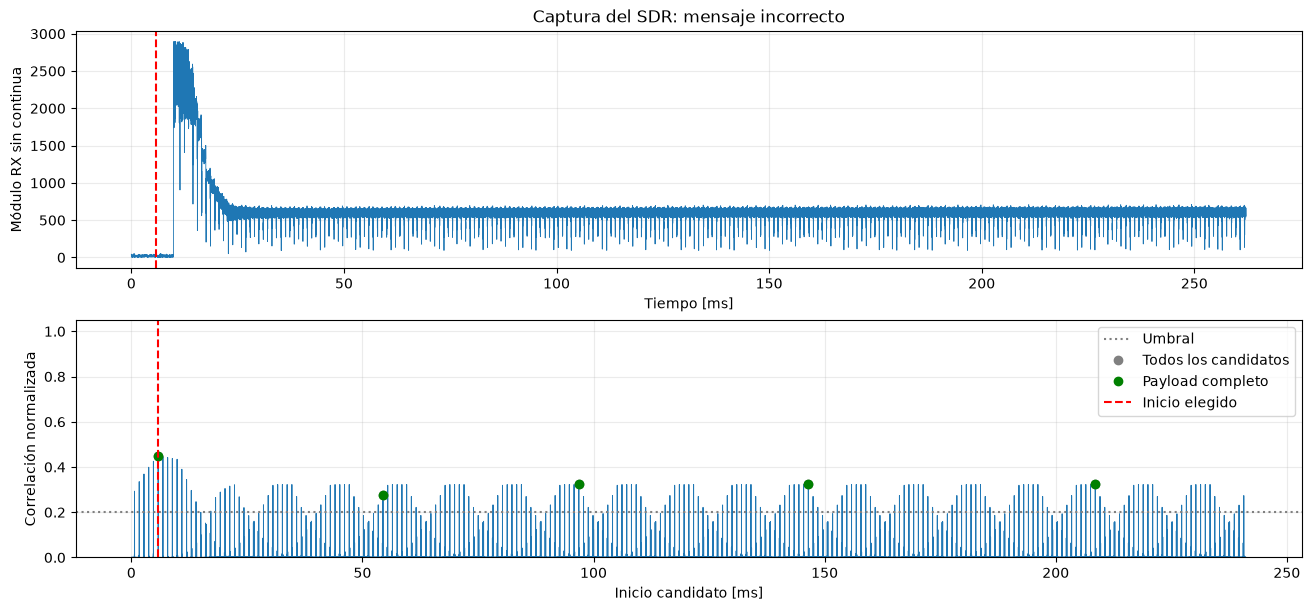

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), constrained_layout=True)
# Reducimos sólo los puntos dibujados; el detector usó la captura completa.
paso_rx = max(1, len(recibida_rx) // 20_000)
axes[0].plot(tiempo_rx[::paso_rx]*1000, np.abs(recibida_rx[::paso_rx]), lw=0.6)
axes[0].set(title=f'Captura del SDR: {estado_rx}', xlabel='Tiempo [ms]', ylabel='Módulo RX sin continua')
axes[1].plot(np.arange(len(puntajes_rx))/fs_rx*1000, puntajes_rx, lw=0.7)
axes[1].axhline(umbral_rx, color='gray', ls=':', label='Umbral')
axes[1].plot(picos_rx/fs_rx*1000, puntajes_rx[picos_rx], 'o', color='gray', label='Todos los candidatos')
axes[1].plot(completos_rx/fs_rx*1000, puntajes_rx[completos_rx], 'go', label='Payload completo')
if inicio_rx is not None:
    for ax in axes:
        ax.axvline(inicio_rx/fs_rx*1000, color='red', ls='--', label='Inicio elegido')
axes[1].set(xlabel='Inicio candidato [ms]', ylabel='Correlación normalizada', ylim=(0, 1.05))
axes[1].legend(loc='upper right')
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()

## 10. Ver la trama recuperada y los bytes decididos

Mismo formato que en la prueba local: señal alineada, rampas reconstruidas con los bytes recuperados y FFT de los diez símbolos después del dechirp. **Las rampas se dibujan a partir de las decisiones**, no son una medición de frecuencia instantánea; la cabecera se muestra con su forma conocida. La amplitud RX se conserva, no se obliga a estar entre −1 y +1.

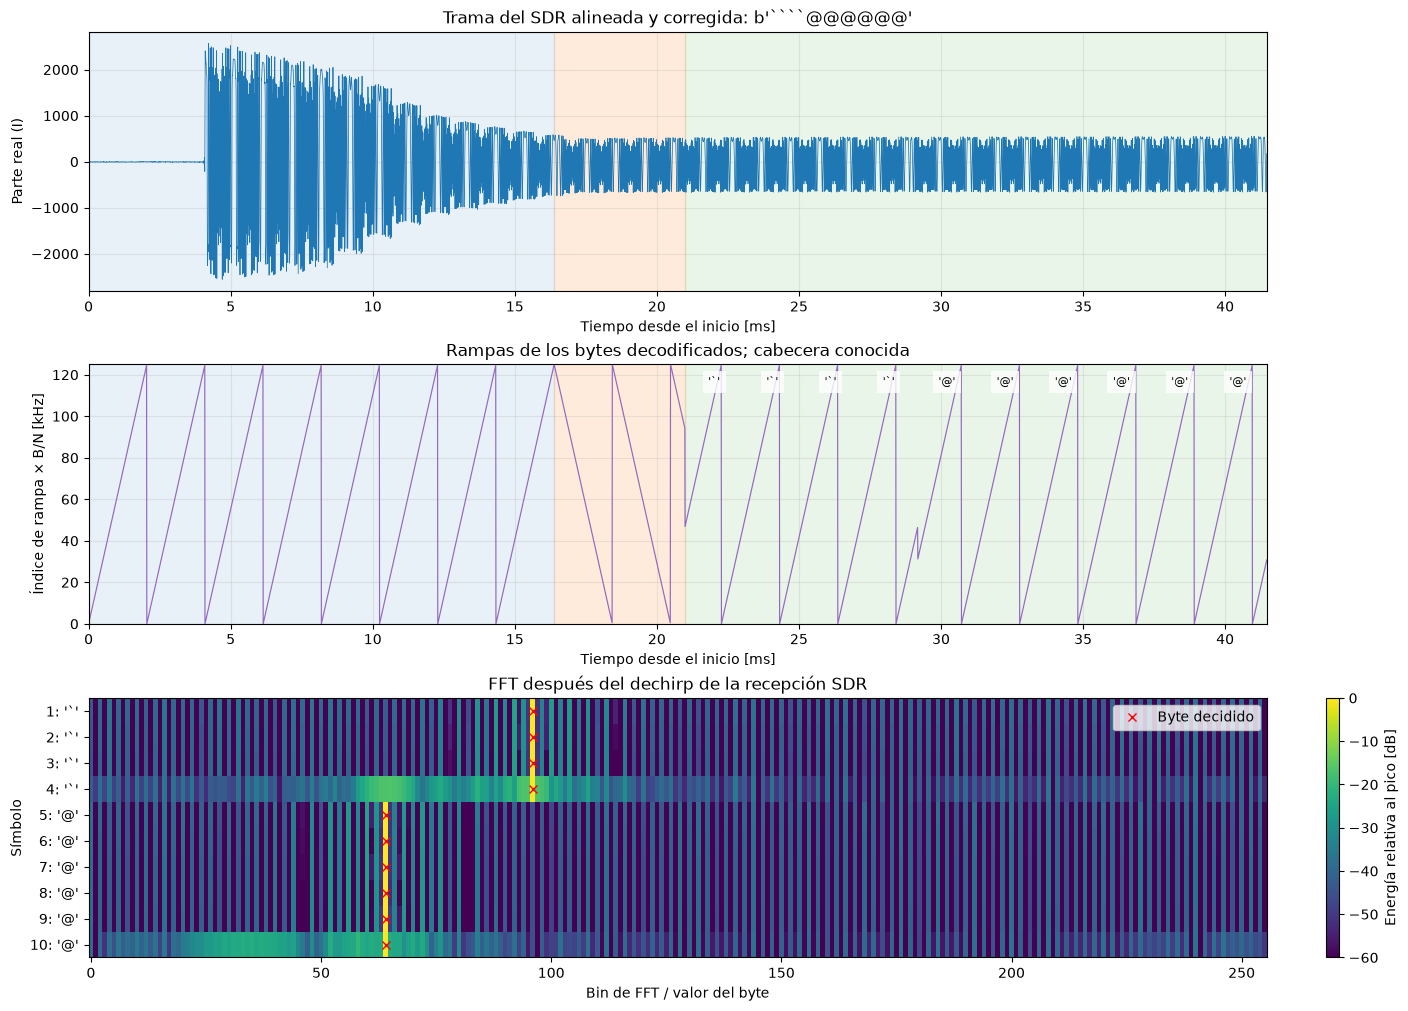

In [17]:
if mensaje_rx is None:
    print('No hay una trama completa detectada para graficar su demodulación.')
else:
    tiempo_trama_rx = np.arange(len(trama_recuperada_rx)) / B * 1000
    rampa_payload_rx = np.concatenate([np.mod(valor + k, N) * B / N for valor in valores_rx])
    rampa_decodificada_rx = np.concatenate((np.tile(rampa_up, 8), rampa_down, rampa_down,
                                            rampa_down[:N // 4], rampa_payload_rx))
    fig, axes = plt.subplots(3, 1, figsize=(14, 10), constrained_layout=True)
    axes[0].plot(tiempo_trama_rx, trama_recuperada_rx.real, lw=0.55)
    axes[0].set(title=f'Trama del SDR alineada y corregida: {mensaje_rx!r}',
                xlabel='Tiempo desde el inicio [ms]', ylabel='Parte real (I)')
    axes[1].plot(tiempo_trama_rx, rampa_decodificada_rx / 1000, lw=0.85, color='tab:purple')
    axes[1].set(title='Rampas de los bytes decodificados; cabecera conocida',
                xlabel='Tiempo desde el inicio [ms]', ylabel='Índice de rampa × B/N [kHz]', ylim=(0, B/1000))
    for ax in axes[:2]:
        ax.axvspan(0, len(preambulo)/B*1000, color='tab:blue', alpha=0.1)
        ax.axvspan(len(preambulo)/B*1000, len(cabecera)/B*1000, color='tab:orange', alpha=0.15)
        ax.axvspan(len(cabecera)/B*1000, len(trama)/B*1000, color='tab:green', alpha=0.1)
        ax.set_xlim(0, len(trama)/B*1000)
        ax.grid(alpha=0.25)
    for posicion, valor in enumerate(valores_rx):
        centro_ms = (len(cabecera) + (posicion + 0.5)*N) / B * 1000
        axes[1].text(centro_ms, 0.92*B/1000, repr(chr(valor)), ha='center', fontsize=8,
                     bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none'})

    energia_rx = np.abs(np.asarray(espectros_rx))**2
    energia_db_rx = 10*np.log10(np.maximum(energia_rx / np.maximum(energia_rx.max(axis=1, keepdims=True), 1e-30), 1e-12))
    imagen = axes[2].imshow(energia_db_rx, aspect='auto', interpolation='nearest', vmin=-60, vmax=0)
    axes[2].plot(valores_rx, np.arange(cantidad_bytes), 'rx', label='Byte decidido')
    axes[2].set(title='FFT después del dechirp de la recepción SDR', xlabel='Bin de FFT / valor del byte', ylabel='Símbolo')
    axes[2].set_yticks(np.arange(cantidad_bytes), [f'{i+1}: {chr(v)!r}' for i, v in enumerate(valores_rx)])
    axes[2].legend(loc='upper right')
    fig.colorbar(imagen, ax=axes[2], label='Energía relativa al pico [dB]')
    plt.show()